# Step 14 — A fair test: does attention earn its place?

Earlier evidence on this question was scattered: notebook 02 tested it properly (paired, 5 seeds,
significance tests) but on **one dataset**; notebooks 07/08 covered 8 datasets but with 3 seeds,
no significance tests, only causal attention, and a 60-epoch cap that cut the slow-converging
averaging arm short. This notebook is the single, purpose-built experiment that settles it.

### The question
At the same size, on the same data and seeds, with the same training settings — does any form of
attention beat simply averaging the experts, **consistently across datasets**?

### Arms (all: the same 16 feature-bagged experts + PLR embeddings, i.e. v4 as it actually runs)

| Arm | Combines expert opinions by | Params (CA) | Role |
|---|---|---|---|
| `meanpool` | plain average, small head | ~25k | what extra parameters alone buy |
| `meanpool_wide` | plain average, head widened to attention's size | ~51k | **the size-matched control** |
| `bidirectional` | attention, every expert sees every other | ~51k | attention without order |
| `causal` | attention, expert *i* sees only experts before it | ~51k | differs from `bidirectional` ONLY by the mask |
| `causal_ds` | causal + every position trained to predict | ~51k | causal attention's best shot (the V2 recipe) |

### Datasets (exact published splits)

| Key | Dataset | Train rows | Features | Task |
|---|---|---|---|---|
| CA | California Housing | 13k | 8 | regression (RMSE) |
| AD | Adult | 26k | 108 (one-hot) | binary (accuracy) |
| HI | Higgs Small | 63k | 28 | binary (accuracy) |
| JA | Jannis | 54k | 54 | 4-class (accuracy) |

### Identical for every arm
Same splits · same 5 seeds (each seed gives **bit-identical expert weights in every arm**, so
comparisons are paired) · lr 1e-3 · batch 512 · weight decay 1e-4 · up to **200 epochs**, early
stopping after 20 without validation improvement · test set touched once, for reporting.

### Decision rule — fixed BEFORE any result is seen
* **"Attention earns its place"**: causal or causal+deep-supervision beats same-size averaging,
  paired p < 0.05, on **at least 3 of 4** datasets.
* **"Attention does not earn its place"**: it does so on **at most 1** dataset.
* Otherwise: **"dataset-dependent"** — and that is what gets reported.

## 0. Setup

In [1]:
import os, sys, time, json, subprocess, warnings
warnings.filterwarnings("ignore")
PROJECT_DIR = os.getcwd(); sys.path.insert(0, PROJECT_DIR)
os.environ["PYTHONPATH"] = PROJECT_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

import benchmarks, benchmarks_rtdl
from training import get_device
from weak_learners import WeakLearnerConfig
from attention import AttentionConfig
from embeddings import EmbeddingConfig
from model import make_arm
from results import save_report
from plotting import apply_style, plot_bar_comparison, role_color

DEVICE = get_device()

# Knobs, overridable from the shell so a headless run needs no edits. Smoke test:
#   SRP_SUBSAMPLE=1500 SRP_SEEDS=2 SRP_EPOCHS=3 SRP_PATIENCE=2 jupyter nbconvert --execute ...
KEYS      = os.environ.get("SRP_KEYS", "CA,AD,HI,JA").split(",")
ARMS      = os.environ.get("SRP_ARMS", "meanpool,meanpool_wide,bidirectional,causal,causal_ds").split(",")
SEEDS     = tuple(range(int(os.environ.get("SRP_SEEDS", "5"))))
EPOCHS    = int(os.environ.get("SRP_EPOCHS", "200"))
PATIENCE  = int(os.environ.get("SRP_PATIENCE", "20"))
SUBSAMPLE = int(os.environ.get("SRP_SUBSAMPLE", "0")) or None

# Identical for every arm (notebook 07/08's architecture; only the budget is longer).
ENS_KW   = dict(num_learners=16, hidden_dim=16, embed_dim=32, depth=1, dropout=0.1, feature_frac=0.7)
ATT_KW   = dict(embed_dim=32, num_heads=4, attn_depth=2, ff_mult=4, dropout=0.1, need_weights=False)
EMB_KW   = dict(mode="periodic", d_embedding=8, n_frequencies=16, sigma=0.1)
TRAIN_KW = dict(epochs=EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=512, weight_decay=1e-4)

LOADER = {"CA": benchmarks_rtdl, "AD": benchmarks_rtdl, "JA": benchmarks_rtdl, "HI": benchmarks}
ARM_LABEL = {"meanpool": "Averaging\n(small head)", "meanpool_wide": "Averaging\n(big head)",
             "bidirectional": "Bidirectional\nattention", "causal": "Causal\nattention",
             "causal_ds": "Causal +\ndeep sup."}
ARM_COLOR = {"meanpool": role_color("PlainMLP"), "meanpool_wide": role_color("meanpool"),
             "bidirectional": role_color("bidirectional"), "causal": role_color("causal"),
             "causal_ds": role_color("causal_ds")}
SIZE_MATCHED = [a for a in ("meanpool_wide", "bidirectional", "causal", "causal_ds") if a in ARMS]

THREADS_PER_JOB = 2
N_JOBS = int(os.environ.get("SRP_JOBS", "0")) or (
    3 if DEVICE.type == "cuda" else max(1, min(8, (os.cpu_count() or 2) // THREADS_PER_JOB)))

RUN_DIR = os.path.join(PROJECT_DIR, "runs"); os.makedirs(RUN_DIR, exist_ok=True)
STAMP = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = os.path.join(RUN_DIR, f"15_progress_{STAMP}.log")
_latest = os.path.join(RUN_DIR, "15_progress.log")
if os.path.islink(_latest) or os.path.exists(_latest):
    os.remove(_latest)
os.symlink(os.path.basename(LOG_PATH), _latest)
REPORT_DIR = os.path.join(PROJECT_DIR, "results", "attention_fair_test")
FIG_DIR = os.path.join(os.path.dirname(PROJECT_DIR), "figures")

def log(msg):
    print(msg, flush=True)
    with open(LOG_PATH, "a") as f: f.write(time.strftime("%H:%M:%S ") + msg + "\n")
def show(df, fmt=None, style=None):
    try:
        s = df.style.format(fmt or {}, na_rep="—"); display(style(s) if style else s)
    except (AttributeError, ImportError):
        display(df.round(4))

apply_style()
gpu = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only"
log(f"device: {DEVICE} ({gpu}) | keys={KEYS} | arms={ARMS} | seeds={len(SEEDS)} | "
    f"epochs<={EPOCHS} patience={PATIENCE} | {N_JOBS} workers")
if SUBSAMPLE:
    log(f"SMOKE TEST: {SUBSAMPLE} rows per split -- numbers below are NOT real results.")

device: cuda (NVIDIA RTX A4000) | keys=['CA', 'AD', 'HI', 'JA'] | arms=['meanpool', 'meanpool_wide', 'bidirectional', 'causal', 'causal_ds'] | seeds=5 | epochs<=200 patience=20 | 3 workers


## 1. Is the architecture correct? Run its own self-tests first

If causal attention were buggy (future experts leaking into the past, the mask silently off,
capacity not matched), any comparison below would be meaningless. Both modules test themselves;
this cell refuses to continue if any check fails.

In [2]:
for module in ("attention.py", "model.py"):
    out = subprocess.run([sys.executable, module], cwd=PROJECT_DIR, capture_output=True, text=True)
    text = out.stdout + out.stderr
    n_pass, n_fail = text.count("PASS"), text.count("FAIL")
    log(f"  {module:14s} {n_pass} PASS, {n_fail} FAIL")
    assert out.returncode == 0 and n_fail == 0 and n_pass > 0, text[-3000:]
log("self-tests passed: causal mask blocks every future expert, capacity matching holds")

  attention.py   5 PASS, 0 FAIL


  model.py       13 PASS, 0 FAIL


self-tests passed: causal mask blocks every future expert, capacity matching holds


## 2. Data — exact published splits

In [3]:
DATA, ARRAYS = {}, {}
for k in KEYS:
    d = LOADER[k].load_benchmark(k)
    a = d.arrays()
    if SUBSAMPLE:
        n = SUBSAMPLE
        a = {"Xtr": a["Xtr"][:n], "ytr": a["ytr"][:n], "Xva": a["Xva"][:n // 2], "yva": a["yva"][:n // 2],
             "Xte": a["Xte"][:n], "yte": a["yte"][:n]}
    DATA[k], ARRAYS[k] = d, a
    log(d.summary())
HIB = {k: LOADER[k].higher_is_better(k) for k in KEYS}
METRIC = {k: ("rmse" if DATA[k].task == "regression" else "acc") for k in KEYS}

CA California Housing regression features=  8 train=13,209 val=3,303 test=4,128


AD Adult              binary     features=108 train=26,048 val=6,513 test=16,281  classes=2


HI Higgs Small        binary     features= 28 train=62,751 val=15,688 test=19,610  classes=2


JA Jannis             multiclass features= 54 train=53,588 val=13,398 test=16,747  classes=4


## 3. Are the arms really the same size?

Built on seed 0 for every dataset. The four size-matched arms must be within 1% of each other,
otherwise "attention vs averaging" would secretly also be "bigger vs smaller".

In [4]:
rows = []
for k in KEYS:
    d = DATA[k]
    row = {"dataset": d.label}
    for arm in ARMS:
        torch.manual_seed(0)
        m = make_arm(arm, d.n_features, WeakLearnerConfig(**ENS_KW, seed=0, batched=True),
                     AttentionConfig(**ATT_KW), task=d.task, output_dim=d.output_dim,
                     embedding=EmbeddingConfig(**EMB_KW))
        row[arm] = m.num_parameters()
    rows.append(row)
PARAMS = pd.DataFrame(rows).set_index("dataset")
show(PARAMS, {a: "{:,.0f}" for a in ARMS})
for ds, r in PARAMS.iterrows():
    vals = [r[a] for a in SIZE_MATCHED]
    spread = (max(vals) - min(vals)) / max(vals)
    assert spread < 0.01, f"{ds}: size-matched arms differ by {spread:.2%}"
log("size check passed: size-matched arms within 1% on every dataset")

,meanpool,meanpool_wide,bidirectional,causal,causal_ds
dataset,,,,,
California Housing,"24,641","50,637","50,689","50,689","50,689"
Adult,"196,001","221,997","222,049","222,049","222,049"
Higgs Small,"58,913","84,909","84,961","84,961","84,961"
Jannis,"103,156","129,167","129,204","129,204","129,204"


size check passed: size-matched arms within 1% on every dataset


## 4. Train everything

One job = one (dataset, arm, seed). Every job builds its model right after `torch.manual_seed(seed)`,
which is what gives every arm bit-identical experts for that seed. Besides the test score, each job
records its best epoch (to detect undertraining), its wall-clock time, and — for attention arms —
how evenly the readout position spreads its attention (1.0 = uniform = the same as averaging).

In [5]:
def run_one(key, arm, seed, arrays, task, output_dim, n_features, y_std,
            ens_kw, att_kw, emb_kw, train_kw, device_str, project_dir, threads):
    import sys, time
    if project_dir not in sys.path: sys.path.insert(0, project_dir)
    import numpy as np, torch
    from weak_learners import WeakLearnerConfig
    from attention import AttentionConfig
    from embeddings import EmbeddingConfig
    from model import make_arm
    from training import train_model, evaluate, to_tensors
    torch.set_num_threads(threads)
    data = to_tensors(arrays, device_str)
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_arm(arm, n_features, WeakLearnerConfig(**ens_kw, seed=seed, batched=True),
                     AttentionConfig(**att_kw), task=task, output_dim=output_dim,
                     embedding=EmbeddingConfig(**emb_kw))
    t0 = time.time()
    model, hist = train_model(model, data, seed=seed, **train_kw)
    test = evaluate(model, data["Xte"], arrays["yte"], task)
    score = test["rmse"] * y_std if task == "regression" else test["acc"]   # RMSE in original units

    entropy = None
    if model.stage is not None:
        model.eval()
        with torch.no_grad():
            out = model(data["Xte"][:2048], need_weights=True)
        K = out["attn"][0].shape[-1]
        ent = []
        for a in out["attn"]:
            p = a[:, -1, :].clamp_min(1e-12)                # the readout (last) position's row
            ent.append(float((-(p * p.log()).sum(-1) / np.log(K)).mean()))
        entropy = float(np.mean(ent))
    return {"key": key, "arm": arm, "seed": seed, "score": score,
            "best_epoch": hist["best_epoch"] + 1, "epochs_run": hist["epochs_run"],
            "best_val_loss": float(hist["val"][hist["best_epoch"]]),
            "seconds": time.time() - t0, "n_params": model.num_parameters(), "entropy": entropy}

SLOW = {"JA": 0, "HI": 1, "AD": 2, "CA": 3}
jobs = [(k, a, s) for k in KEYS for a in ARMS for s in SEEDS]
jobs.sort(key=lambda j: (SLOW.get(j[0], 9), j[1] in ("meanpool", "meanpool_wide")))   # slowest first
log(f"{len(jobs)} runs on {N_JOBS} workers ({DEVICE}) ...")

t0, RES = time.time(), []
for r in Parallel(n_jobs=N_JOBS, return_as="generator")(
        delayed(run_one)(k, a, s, ARRAYS[k], DATA[k].task, DATA[k].output_dim, DATA[k].n_features,
                         DATA[k].y_std, ENS_KW, ATT_KW, EMB_KW, TRAIN_KW, str(DEVICE),
                         PROJECT_DIR, THREADS_PER_JOB)
        for k, a, s in jobs):
    RES.append(r)
    save_report(os.path.join(REPORT_DIR, r["key"], r["arm"], f"seed{r['seed']}"),
                dataset=r["key"], label=DATA[r["key"]].label, arm=r["arm"], seed=r["seed"],
                source="reproduced", source_ref="notebook 15 (attention fair test)"
                + (" [SMOKE TEST]" if SUBSAMPLE else ""),
                config={"ens": ENS_KW, "att": ATT_KW, "emb": EMB_KW, "train": TRAIN_KW},
                n_parameters=r["n_params"], metrics={"test": {METRIC[r["key"]]: r["score"]}},
                champion_metric=f"test_{METRIC[r['key']]}", champion_value=r["score"],
                higher_is_better=HIB[r["key"]], time_seconds=r["seconds"], checkpoint=None)
    log(f"  [{len(RES):3d}/{len(jobs)}] {r['key']} {r['arm']:14s} seed {r['seed']}  "
        f"{METRIC[r['key']]} {r['score']:.4f}  best epoch {r['best_epoch']:3d}/{r['epochs_run']:3d}  "
        f"({r['seconds']/60:.1f} min)  elapsed {(time.time()-t0)/60:.1f} min")
R = pd.DataFrame(RES)
log(f"all runs done in {(time.time()-t0)/60:.1f} min")

100 runs on 3 workers (cuda) ...


  [  1/100] JA bidirectional  seed 0  acc 0.7180  best epoch   8/ 28  (0.8 min)  elapsed 0.9 min


  [  2/100] JA bidirectional  seed 1  acc 0.7211  best epoch  11/ 31  (0.9 min)  elapsed 1.0 min


  [  3/100] JA bidirectional  seed 2  acc 0.7211  best epoch  11/ 31  (0.9 min)  elapsed 1.0 min


  [  4/100] JA bidirectional  seed 3  acc 0.7167  best epoch  11/ 31  (0.9 min)  elapsed 1.8 min


...

  [ 97/100] CA meanpool_wide  seed 1  rmse 0.4649  best epoch 125/145  (0.4 min)  elapsed 20.0 min


  [ 98/100] CA meanpool_wide  seed 2  rmse 0.4666  best epoch  97/117  (0.3 min)  elapsed 20.2 min


  [ 99/100] CA meanpool_wide  seed 3  rmse 0.4692  best epoch 117/137  (0.3 min)  elapsed 20.2 min


  [100/100] CA meanpool_wide  seed 4  rmse 0.4798  best epoch 166/186  (0.4 min)  elapsed 20.5 min


all runs done in 20.5 min


## 5. Did every run actually finish learning?

A run whose best epoch is within the last `PATIENCE` epochs of the cap was still improving when
training stopped, so its score understates that arm. This was the flaw in notebook 08.

In [6]:
R["undertrained"] = R["best_epoch"] > (EPOCHS - PATIENCE)
flag = R[R.undertrained]
if len(flag):
    log(f"WARNING: {len(flag)} run(s) may be undertrained (best epoch near the {EPOCHS}-epoch cap):")
    show(flag[["key", "arm", "seed", "best_epoch", "epochs_run"]])
else:
    log(f"convergence check passed: every run early-stopped well before the {EPOCHS}-epoch cap")
show(R.groupby(["key", "arm"])["best_epoch"].agg(["mean", "max"]).unstack("arm").round(0))

,key,arm,seed,best_epoch,epochs_run
94,CA,meanpool,4,193,200


## 6. Results

In [7]:
agg = R.groupby(["key", "arm"])["score"].agg(["mean", "std"])
table = pd.DataFrame({DATA[k].label + (" (RMSE↓)" if not HIB[k] else " (acc↑)"):
                      [f"{agg.loc[(k, a), 'mean']:.4f} ± {agg.loc[(k, a), 'std']:.4f}" for a in ARMS]
                      for k in KEYS}, index=[ARM_LABEL[a].replace(chr(10), " ") for a in ARMS])
print(f"Test scores, mean ± std over {len(SEEDS)} seeds")
show(table)

mins = R.groupby(["key", "arm"])["seconds"].mean().unstack("arm")[ARMS] / 60
mins.index = [DATA[k].label for k in mins.index]
print("\nMean minutes per run")
show(mins, {a: "{:.1f}" for a in ARMS})

Test scores, mean ± std over 5 seeds


,California Housing (RMSE↓),Adult (acc↑),Higgs Small (acc↑),Jannis (acc↑)
Averaging (small head),0.4796 ± 0.0108,0.8594 ± 0.0005,0.7250 ± 0.0015,0.7194 ± 0.0019
Averaging (big head),0.4706 ± 0.0059,0.8594 ± 0.0006,0.7248 ± 0.0017,0.7207 ± 0.0027
Bidirectional attention,0.4828 ± 0.0073,0.8613 ± 0.0009,0.7225 ± 0.0008,0.7191 ± 0.0019
Causal attention,0.4778 ± 0.0050,0.8608 ± 0.0006,0.7224 ± 0.0017,0.7194 ± 0.0009
Causal + deep sup.,0.4878 ± 0.0034,0.8601 ± 0.0011,0.7227 ± 0.0017,0.7179 ± 0.0029



Mean minutes per run


arm,meanpool,meanpool_wide,bidirectional,causal,causal_ds
Adult,0.2,0.2,0.5,0.5,0.5
California Housing,0.4,0.4,0.6,0.6,0.7
Higgs Small,0.4,0.5,1.0,1.0,1.2
Jannis,0.3,0.3,0.9,0.9,1.0


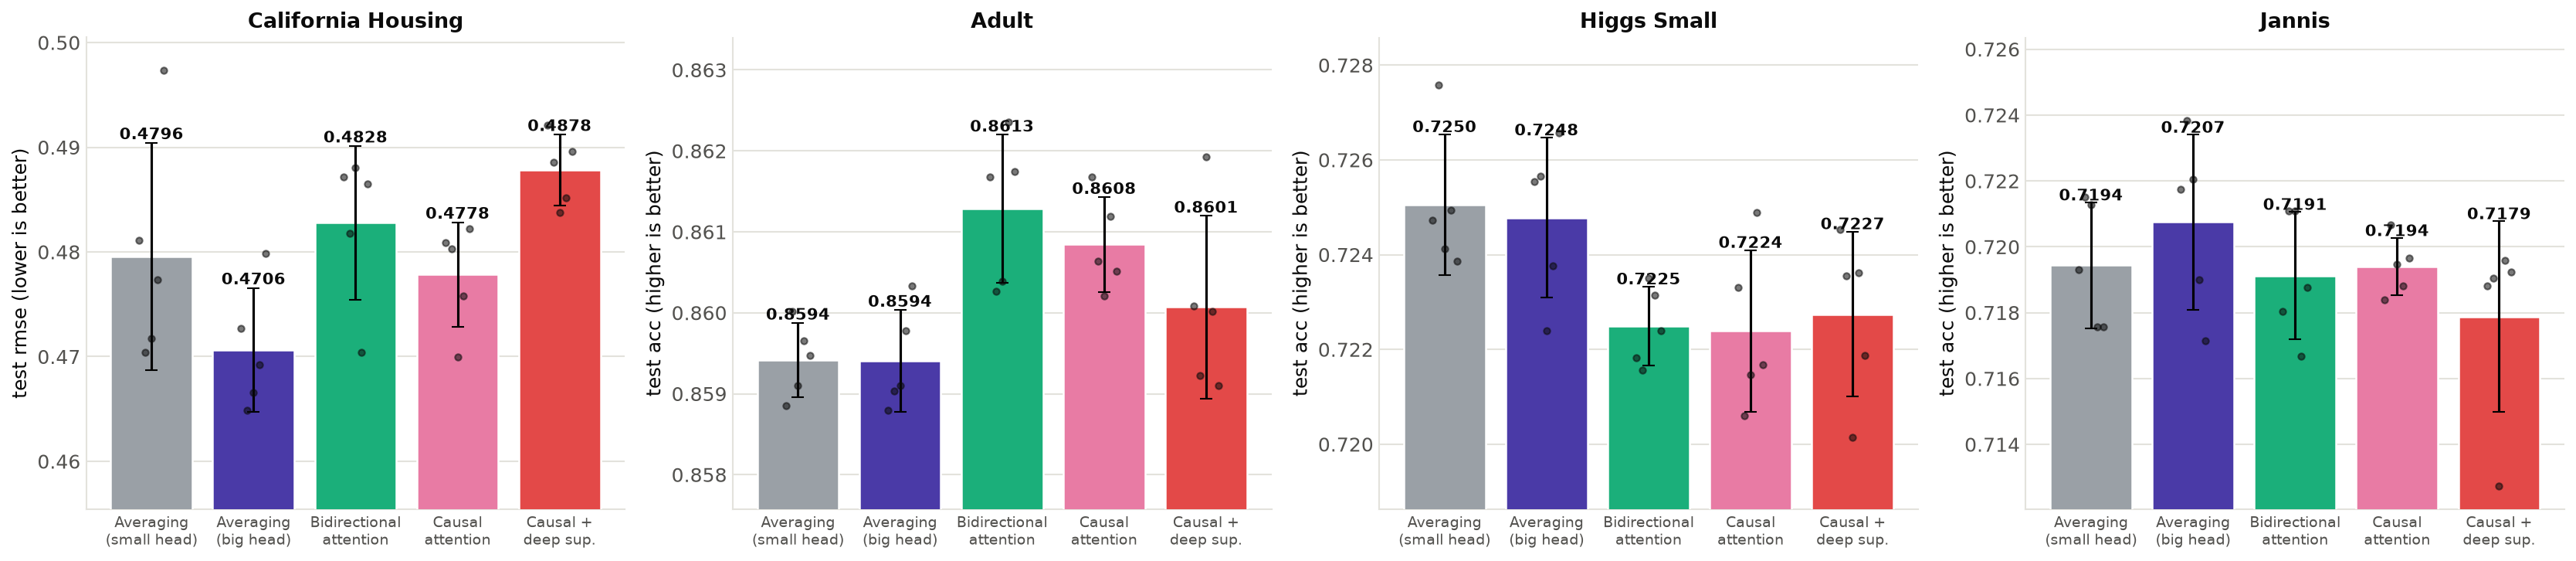

In [8]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(5.6 * len(KEYS), 5.0))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, KEYS):
    means = [agg.loc[(k, a), "mean"] for a in ARMS]
    stds = [agg.loc[(k, a), "std"] for a in ARMS]
    seeds = [R[(R.key == k) & (R.arm == a)]["score"].values for a in ARMS]
    plot_bar_comparison([ARM_LABEL[a] for a in ARMS], means, stds=stds,
                        colors=[ARM_COLOR[a] for a in ARMS], seed_values=seeds,
                        ylabel=f"test {METRIC[k]} ({'higher' if HIB[k] else 'lower'} is better)",
                        title=DATA[k].label, ax=ax)
    lo = min(m - (s if s == s else 0) for m, s in zip(means, stds))
    hi = max(m + (s if s == s else 0) for m, s in zip(means, stds))
    pad = (hi - lo) * 0.35 + 1e-6
    ax.set_ylim(lo - pad, hi + pad)
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
if not SUBSAMPLE:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, "attention_fair_test.pdf"), dpi=200)
    fig.savefig(os.path.join(FIG_DIR, "attention_fair_test.png"), dpi=200)
plt.show()

## 7. Paired significance tests

For each dataset: difference per seed (same seed = same experts), paired t-test over the seeds.
Differences are signed so that **positive always means A is better**, whether the metric is
accuracy or RMSE.

In [9]:
COMPARISONS = [
    ("Capacity: big head vs small head",        "meanpool_wide", "meanpool"),
    ("Bidirectional vs same-size averaging",    "bidirectional", "meanpool_wide"),
    ("Causal vs same-size averaging",           "causal",        "meanpool_wide"),
    ("Causal + deep sup. vs same-size averaging", "causal_ds",   "meanpool_wide"),
    ("Does the mask matter? causal vs bidirectional", "causal",  "bidirectional"),
    ("Deep supervision: causal+DS vs causal",   "causal_ds",     "causal"),
]
COMPARISONS = [c for c in COMPARISONS if c[1] in ARMS and c[2] in ARMS]

rows = []
for k in KEYS:
    wide = R[R.key == k].pivot(index="seed", columns="arm", values="score")
    sign = 1.0 if HIB[k] else -1.0
    for name, a, b in COMPARISONS:
        d = sign * (wide[a] - wide[b]).values
        p = stats.ttest_rel(wide[a], wide[b]).pvalue if len(d) > 1 else np.nan
        verdict = ("A better" if p < 0.05 and d.mean() > 0 else
                   "B better" if p < 0.05 and d.mean() < 0 else "no real difference")
        rows.append({"dataset": DATA[k].label, "comparison": name, "A": a, "B": b,
                     "mean advantage of A": d.mean(), "A wins": f"{int((d > 0).sum())}/{len(d)}",
                     "p": p, "verdict": verdict})
TESTS = pd.DataFrame(rows)
show(TESTS.set_index(["comparison", "dataset"]).drop(columns=["A", "B"]).sort_index(),
     {"mean advantage of A": "{:+.4f}", "p": "{:.3f}"},
     style=lambda s: s.map(lambda v: {"A better": "background-color:#d8f5e3",
                                      "B better": "background-color:#fbdada"}.get(v, ""),
                           subset=["verdict"]))

### 7.1 Pooled across all datasets

The per-dataset tests have only 5 seeds each. Pooling all (dataset, seed) pairs gives one
stronger test per comparison. To pool datasets with different metrics, each difference is
expressed as a **percentage of the baseline arm's score** (sign-corrected, positive = A better),
then a Wilcoxon signed-rank test asks whether A is consistently ahead.

In [10]:
rows = []
for name, a, b in COMPARISONS:
    rel = []
    for k in KEYS:
        wide = R[R.key == k].pivot(index="seed", columns="arm", values="score")
        sign = 1.0 if HIB[k] else -1.0
        rel += list(sign * (wide[a] - wide[b]) / wide[b].abs() * 100)
    rel = np.array(rel)
    p = stats.wilcoxon(rel).pvalue if len(rel) >= 6 and np.any(rel != 0) else np.nan
    rows.append({"comparison": name, "pairs": len(rel), "median % advantage of A": np.median(rel),
                 "A wins": f"{int((rel > 0).sum())}/{len(rel)}", "Wilcoxon p": p})
POOLED = pd.DataFrame(rows).set_index("comparison")
show(POOLED, {"median % advantage of A": "{:+.2f}%", "Wilcoxon p": "{:.4f}"})

,pairs,median % advantage of A,A wins,Wilcoxon p
comparison,,,,
Capacity: big head vs small head,20,+0.11%,13/20,0.0269
Bidirectional vs same-size averaging,20,-0.28%,7/20,0.0240
Causal vs same-size averaging,20,-0.33%,7/20,0.0172
Causal + deep sup. vs same-size averaging,20,-0.30%,6/20,0.0083
Does the mask matter? causal vs bidirectional,20,+0.02%,10/20,0.4209
Deep supervision: causal+DS vs causal,20,-0.17%,6/20,0.0172


## 8. Is the attention actually doing anything?

In [11]:
att = [a for a in ("bidirectional", "causal", "causal_ds") if a in ARMS]
if att:
    ent = R[R.arm.isin(att)].groupby(["key", "arm"])["entropy"].mean().unstack("arm")[att]
    ent.index = [DATA[k].label for k in ent.index]
    print("Readout-position attention entropy (1.0 = perfectly uniform = identical to averaging)")
    show(ent, {a: "{:.3f}" for a in att})

Readout-position attention entropy (1.0 = perfectly uniform = identical to averaging)


arm,bidirectional,causal,causal_ds
Adult,0.920,0.923,0.931
California Housing,0.797,0.799,0.806
Higgs Small,0.800,0.795,0.823
Jannis,0.816,0.811,0.830


## 9. Verdict — applying the pre-registered decision rule

In [12]:
sep = "=" * 92
print(sep); print("VERDICT -- does attention earn its place?"); print(sep)

def beats_averaging(arm):
    t = TESTS[(TESTS.A == arm) & (TESTS.B == "meanpool_wide")]
    return dict(zip(t.dataset, t.verdict == "A better")), dict(zip(t.dataset, t.verdict == "B better"))

causal_arms = [a for a in ("causal", "causal_ds") if a in ARMS]
wins_by_ds = {DATA[k].label: False for k in KEYS}
for arm in causal_arms:
    w, _ = beats_averaging(arm)
    for ds, v in w.items():
        wins_by_ds[ds] = wins_by_ds[ds] or v
n_win = sum(wins_by_ds.values())

for arm in [a for a in ("bidirectional", "causal", "causal_ds") if a in ARMS]:
    w, l = beats_averaging(arm)
    print(f"\n{arm}: beats same-size averaging on {sum(w.values())}/{len(w)} datasets, "
          f"loses on {sum(l.values())}/{len(l)}, ties the rest")
    for ds in w:
        print(f"   {ds:20s} " + ("WINS" if w[ds] else "loses" if l[ds] else "no real difference"))

print(f"\nPre-registered rule: causal or causal+deep-sup. beats same-size averaging (p<0.05) on "
      f"{n_win} of {len(KEYS)} datasets.")
if n_win >= 3:
    print("   -> ATTENTION EARNS ITS PLACE.")
elif n_win <= 1:
    print("   -> ATTENTION DOES NOT EARN ITS PLACE: at the same size, it does not reliably beat averaging.")
else:
    print("   -> DATASET-DEPENDENT: attention helps on some datasets and not others.")

if "meanpool" in ARMS:
    w = TESTS[TESTS.comparison.str.startswith("Capacity")]
    print(f"\nCapacity alone (big head vs small head, no attention) helps on "
          f"{int((w.verdict == 'A better').sum())}/{len(w)} datasets.")
if SUBSAMPLE:
    print("\nSMOKE TEST MODE -- these verdicts are meaningless, the pipeline check is what matters.")
print(sep)

VERDICT -- does attention earn its place?

bidirectional: beats same-size averaging on 1/4 datasets, loses on 1/4, ties the rest
   California Housing   loses
   Adult                WINS
   Higgs Small          no real difference
   Jannis               no real difference

causal: beats same-size averaging on 1/4 datasets, loses on 1/4, ties the rest
   California Housing   loses
   Adult                WINS
   Higgs Small          no real difference
   Jannis               no real difference

causal_ds: beats same-size averaging on 0/4 datasets, loses on 1/4, ties the rest
   California Housing   loses
   Adult                no real difference
   Higgs Small          no real difference
   Jannis               no real difference

Pre-registered rule: causal or causal+deep-sup. beats same-size averaging (p<0.05) on 1 of 4 datasets.
   -> ATTENTION DOES NOT EARN ITS PLACE: at the same size, it does not reliably beat averaging.

Capacity alone (big head vs small head, no attention) help

## 10. Notes

* **One shared learning rate (1e-3) for every arm, by design** — strictly identical settings. If
  attention loses, the one remaining objection is "it needed a different learning rate"; the
  natural follow-up is a per-arm lr pick on validation.
* **Expert order is arbitrary** (notebook 14): the 16 experts are trained jointly, so nothing makes
  expert *i* a correction of experts before it. The causal mask is implemented correctly (section 1),
  but it can only exploit an order that carries information. `causal_ds` is included because deep
  supervision is the one ingredient that gives each position its own job.
* Picking the better of `causal`/`causal_ds` per dataset slightly favours attention in the decision
  rule — deliberately, so that a negative verdict is conservative.